# E2：スナップショットの選択方法と全勾配の推定方法の要因分離（CIFAR-10）

`programs/analysis_e2_factorial.py` を呼び出し，集計結果（表と図）を表示する．対応する実験・プログラムの説明は `programs/ex007_e2_cifar10_snapshot_gradient_factorial/README.md` を参照する．

| | 最終点 | ランダム点 | 平均点 |
|---|---|---|---|
| $ {\mathbf g}_{s} $：全勾配（実線） | SVRG-final | SVRG-random | SVRG-average |
| $ {\mathbf g}_{s} $：平均勾配（破線） | NFG-final | NFG-random | ASA-SVRG |

In [1]:
import os
import sys

sys.path.insert(0, os.path.join(os.getcwd(), "programs"))
import analysis_e2_factorial as a

summary_path = a.write_summary()
print(summary_path)

/home/user/workspace/ASAI_SVRG_programs/programs_review/outputs/e2_factorial_summary.md


## 集計表（outputs/e2_factorial_summary.md）

In [2]:
from IPython.display import Markdown, display

with open(summary_path) as f:
    text = f.read()
display(Markdown(text))

# E2：スナップショットの選択方法と全勾配の推定方法の要因分離（CIFAR-10，集計結果）

CIFAR-10・AlexNet（LayerNorm），$ \eta = 10^{-3} $，バッチサイズ128（$ K = 391 $），48エポック，$ \lambda = 5\times10^{-4} $，`inner_start="snapshot"`．値はシード間の平均 ± 標準誤差である．

- 最終値 (a)：$ \#\mathrm{grad}/N \le 90 $ の最後の評価点（予算をそろえた比較）．全勾配の手法は約30エポック，平均勾配の手法は45エポックの評価点に当たる．
- 最終値 (b)：48エポック目（同じエポック数の比較．全勾配の手法は $ \#\mathrm{grad}/N \approx 145 $，平均勾配の手法は96）．
- 打ち切りの場合は打ち切り直前の評価点を用いる．学習後半の中央値はエポック25〜48の評価点の中央値をシードごとに求めた値である．
- 平均勾配の手法の1エポック目は $ {\mathbf g}_{0} = {\mathbf 0} $，$ {\mathbf w}_{0}^{0} = {\mathbf z}_{0} $ より補正勾配が常に $ {\mathbf 0} $ であり，内側ループが動かない（$ \omega = 0 $）．このエポックの $ \omega $ の比は定義しない．

## 6手法の集計

| 手法 | スナップショット | $ {\mathbf g}_{s} $ | 試行数 | 打ち切り | (a) の評価点のエポック | 最終精度 (a) $ \#\mathrm{grad}/N \le 90 $ | 最終精度 (b) 48エポック | 学習損失 (a) | 学習損失 (b) |
|---|---|---|---:|---:|---:|---:|---:|---:|---:|
| SVRG-final | final | full | 5 | 0 | 29 | 0.7148 ± 0.0041 | 0.7458 ± 0.0052 | 0.7680 ± 0.0105 | 0.3473 ± 0.0153 |
| SVRG-random | random | full | 5 | 0 | 29 | 0.6484 ± 0.0063 | 0.7081 ± 0.0046 | 1.1481 ± 0.0233 | 0.8691 ± 0.0266 |
| SVRG-average | average | full | 5 | 0 | 29 | 0.6619 ± 0.0008 | 0.7217 ± 0.0013 | 1.1148 ± 0.0024 | 0.8265 ± 0.0023 |
| NFG-final | final | averaged | 5 | 0 | 45 | 0.2708 ± 0.0429 | 0.2203 ± 0.0474 | 2.2502 ± 0.1232 | 2.3465 ± 0.1163 |
| NFG-random | random | averaged | 5 | 0 | 45 | 0.2478 ± 0.0389 | 0.2673 ± 0.0470 | 2.3513 ± 0.1061 | 2.2640 ± 0.1343 |
| ASA-SVRG | average | averaged | 5 | 0 | 45 | 0.7116 ± 0.0016 | 0.7187 ± 0.0014 | 0.8856 ± 0.0026 | 0.8452 ± 0.0025 |

| 手法 | 精度の変化量（計画4.4節：エポック25〜48の $ |a_{s}-a_{s-1}| $ の平均） | 精度の変化量（report_044：$ 45 < \#\mathrm{grad}/N \le 90 $ の差の標準偏差） | 近似誤差の中央値（後半） | 相対近似誤差の中央値（後半） | `approx_cos` の中央値（後半） | $ \omega({\mathbf z}_{s})/K $ の中央値（後半） | $ \omega({\mathbf z}_{s})/\omega_{\min} $ の中央値（後半） |
|---|---:|---:|---:|---:|---:|---:|---:|
| SVRG-final | 0.0128 ± 0.0008 | 0.0174 ± 0.0023 | 0（全勾配） | 0（全勾配） | 1（全勾配） | 5.787e-03 ± 1.2e-04 | 3.194139 ± 0.016054 |
| SVRG-random | 0.0100 ± 0.0011 | 0.0130 ± 0.0012 | 0（全勾配） | 0（全勾配） | 1（全勾配） | 2.880e-03 ± 7.6e-05 | 1.842471 ± 0.093571 |
| SVRG-average | 0.0038 ± 0.0001 | 0.0021 ± 0.0002 | 0（全勾配） | 0（全勾配） | 1（全勾配） | 1.389e-03 ± 1.3e-05 | 1.000001 ± 0.000000 |
| NFG-final | 0.0232 ± 0.0052 | 0.0412 ± 0.0138 | 1.954e+00 ± 1.9e+00 | 1.956e-01 ± 1.3e-01 | 0.9518 ± 0.0265 | 1.570e-02 ± 1.5e-02 | 4.018901 ± 0.018980 |
| NFG-random | 0.0228 ± 0.0066 | 0.0444 ± 0.0145 | 6.368e-01 ± 6.3e-01 | 1.439e-01 ± 1.1e-01 | 0.9642 ± 0.0180 | 4.191e-03 ± 2.7e-03 | 1.739430 ± 0.092331 |
| ASA-SVRG | 0.0041 ± 0.0001 | 0.0020 ± 0.0001 | 8.243e-02 ± 2.2e-03 | 2.281e-01 ± 2.2e-03 | 0.9038 ± 0.0024 | 1.312e-03 ± 9.4e-06 | 1.000001 ± 0.000000 |


平均点の手法の $ \omega({\mathbf z}_{s})/\omega_{\min} $ の確認：

- SVRG-average：$ |\omega({\mathbf z}_{s})/\omega_{\min} - 1| $ の最大値 1.159e-06（シードごと：0: 1.16e-06, 1: 1.07e-06, 2: 1.04e-06, 3: 1.03e-06, 4: 1.10e-06）．1から 1e-06 以上ずれたシード：[0, 1, 2, 3, 4]（数値誤差）．
- ASA-SVRG：$ |\omega({\mathbf z}_{s})/\omega_{\min} - 1| $ の最大値 1.385e-06（シードごと：0: 1.37e-06, 1: 1.29e-06, 2: 1.19e-06, 3: 1.39e-06, 4: 1.33e-06）．1から 1e-06 以上ずれたシード：[0, 1, 2, 3, 4]（数値誤差）．


## 対応のある差：近似誤差の効果（同じスナップショット，平均勾配 − 全勾配）

| 比較 | A − B | 指標 | シードごとの差 | 平均 ± 標準誤差 |
|---|---|---|---|---:|
| 近似誤差の効果（最終点） | NFG-final − SVRG-final | 最終精度 (a) | 0: -0.5133, 1: -0.3429, 2: -0.3807, 3: -0.4194, 4: -0.5640 | -0.4441 ± 0.0413 |
| 近似誤差の効果（最終点） | NFG-final − SVRG-final | 最終精度 (b) | 0: -0.5321, 1: -0.6377, 2: -0.4044, 3: -0.4430, 4: -0.6101 | -0.5255 ± 0.0454 |
| 近似誤差の効果（最終点） | NFG-final − SVRG-final | 学習損失 (a) | 0: +1.7458, 1: +1.2102, 2: +1.2907, 3: +1.3877, 4: +1.7767 | 1.4822 ± 0.1174 |
| 近似誤差の効果（最終点） | NFG-final − SVRG-final | 学習損失 (b) | 0: +2.1501, 1: +2.1949, 2: +1.6899, 3: +1.8022, 4: +2.1589 | 1.9992 ± 0.1051 |
| 近似誤差の効果（ランダム点） | NFG-random − SVRG-random | 最終精度 (a) | 0: -0.2810, 1: -0.4854, 2: -0.3426, 3: -0.4211, 4: -0.4732 | -0.4007 ± 0.0391 |
| 近似誤差の効果（ランダム点） | NFG-random − SVRG-random | 最終精度 (b) | 0: -0.3068, 1: -0.5582, 2: -0.3423, 3: -0.4796, 4: -0.5172 | -0.4408 ± 0.0494 |
| 近似誤差の効果（ランダム点） | NFG-random − SVRG-random | 学習損失 (a) | 0: +0.8272, 1: +1.4219, 2: +1.1503, 3: +1.1869, 4: +1.4298 | 1.2032 ± 0.1104 |
| 近似誤差の効果（ランダム点） | NFG-random − SVRG-random | 学習損失 (b) | 0: +0.9873, 1: +1.6539, 2: +1.1420, 3: +1.4347, 4: +1.7564 | 1.3949 ± 0.1465 |
| 近似誤差の効果（平均点） | ASA-SVRG − SVRG-average | 最終精度 (a) | 0: +0.0463, 1: +0.0572, 2: +0.0477, 3: +0.0519, 4: +0.0458 | 0.0498 ± 0.0021 |
| 近似誤差の効果（平均点） | ASA-SVRG − SVRG-average | 最終精度 (b) | 0: -0.0030, 1: -0.0036, 2: -0.0045, 3: -0.0025, 4: -0.0014 | -0.0030 ± 0.0005 |
| 近似誤差の効果（平均点） | ASA-SVRG − SVRG-average | 学習損失 (a) | 0: -0.2261, 1: -0.2324, 2: -0.2334, 3: -0.2266, 4: -0.2277 | -0.2293 ± 0.0015 |
| 近似誤差の効果（平均点） | ASA-SVRG − SVRG-average | 学習損失 (b) | 0: +0.0205, 1: +0.0176, 2: +0.0188, 3: +0.0188, 4: +0.0178 | 0.0187 ± 0.0005 |


## 対応のある差：スナップショットの効果（同じ $ {\mathbf g}_{s} $ の推定方法）

| 比較 | A − B | 指標 | シードごとの差 | 平均 ± 標準誤差 |
|---|---|---|---|---:|
| スナップショットの効果（全勾配，平均点 − ランダム点） | SVRG-average − SVRG-random | 最終精度 (a) | 0: +0.0077, 1: -0.0010, 2: +0.0161, 3: +0.0360, 4: +0.0083 | 0.0134 ± 0.0063 |
| スナップショットの効果（全勾配，平均点 − ランダム点） | SVRG-average − SVRG-random | 最終精度 (b) | 0: +0.0219, 1: +0.0093, 2: +0.0085, 3: +0.0266, 4: +0.0018 | 0.0136 ± 0.0046 |
| スナップショットの効果（全勾配，平均点 − ランダム点） | SVRG-average − SVRG-random | 学習損失 (a) | 0: -0.0179, 1: +0.0006, 2: -0.0323, 3: -0.1260, 4: +0.0092 | -0.0333 ± 0.0243 |
| スナップショットの効果（全勾配，平均点 − ランダム点） | SVRG-average − SVRG-random | 学習損失 (b) | 0: -0.0897, 1: -0.0577, 2: -0.0142, 3: -0.1014, 4: +0.0500 | -0.0426 ± 0.0276 |
| スナップショットの効果（全勾配，最終点 − ランダム点） | SVRG-final − SVRG-random | 最終精度 (a) | 0: +0.0537, 1: +0.0684, 2: +0.0607, 3: +0.0899, 4: +0.0592 | 0.0664 ± 0.0063 |
| スナップショットの効果（全勾配，最終点 − ランダム点） | SVRG-final − SVRG-random | 最終精度 (b) | 0: +0.0400, 1: +0.0395, 2: +0.0394, 3: +0.0577, 4: +0.0118 | 0.0377 ± 0.0074 |
| スナップショットの効果（全勾配，最終点 − ランダム点） | SVRG-final − SVRG-random | 学習損失 (a) | 0: -0.3544, 1: -0.3823, 2: -0.3713, 3: -0.4586, 4: -0.3341 | -0.3801 ± 0.0212 |
| スナップショットの効果（全勾配，最終点 − ランダム点） | SVRG-final − SVRG-random | 学習損失 (b) | 0: -0.5436, 1: -0.5462, 2: -0.5239, 3: -0.6053, 4: -0.3898 | -0.5218 ± 0.0357 |
| スナップショットの効果（平均勾配，平均点 − ランダム点） | ASA-SVRG − NFG-random | 最終精度 (a) | 0: +0.3350, 1: +0.5416, 2: +0.4064, 3: +0.5090, 4: +0.5273 | 0.4639 ± 0.0400 |
| スナップショットの効果（平均勾配，平均点 − ランダム点） | ASA-SVRG − NFG-random | 最終精度 (b) | 0: +0.3257, 1: +0.5639, 2: +0.3463, 3: +0.5037, 4: +0.5176 | 0.4514 ± 0.0483 |
| スナップショットの効果（平均勾配，平均点 − ランダム点） | ASA-SVRG − NFG-random | 学習損失 (a) | 0: -1.0712, 1: -1.6538, 2: -1.4159, 3: -1.5395, 4: -1.6484 | -1.4658 ± 0.1078 |
| スナップショットの効果（平均勾配，平均点 − ランダム点） | ASA-SVRG − NFG-random | 学習損失 (b) | 0: -1.0565, 1: -1.6940, 2: -1.1374, 3: -1.5173, 4: -1.6887 | -1.4188 ± 0.1358 |


## 平均勾配の3手法における $ \omega $ と近似誤差の順序（学習後半の中央値）

| シード | $ \omega/K $ の小さい順 | 近似誤差の小さい順 | 相対近似誤差の小さい順 | 順序の一致（近似誤差） | 順序の一致（相対近似誤差） |
|---:|---|---|---|---|---|
| 0 | NFG-final < ASA-SVRG < NFG-random | NFG-final < NFG-random < ASA-SVRG | NFG-final < NFG-random < ASA-SVRG | × | × |
| 1 | NFG-random < ASA-SVRG < NFG-final | NFG-random < ASA-SVRG < NFG-final | NFG-random < ASA-SVRG < NFG-final | ○ | ○ |
| 2 | ASA-SVRG < NFG-final < NFG-random | ASA-SVRG < NFG-final < NFG-random | NFG-final < ASA-SVRG < NFG-random | ○ | × |
| 3 | ASA-SVRG < NFG-final < NFG-random | NFG-final < NFG-random < ASA-SVRG | NFG-final < NFG-random < ASA-SVRG | × | × |
| 4 | NFG-random < NFG-final < ASA-SVRG | NFG-final < NFG-random < ASA-SVRG | NFG-final < NFG-random < ASA-SVRG | × | × |

一致したシード数：近似誤差 2/5，相対近似誤差 1/5．シード平均の順序：$ \omega/K $ は ASA-SVRG < NFG-random < NFG-final，近似誤差は ASA-SVRG < NFG-random < NFG-final．

全エポック（2〜48）をまとめた，シードごとの $ \log_{10}(\omega/K) $ と $ \log_{10}\|{\mathbf e}_{s}\|^{2} $ の相関係数（手法ごと）：

- NFG-final：0.721 ± 0.125
- NFG-random：0.764 ± 0.089
- ASA-SVRG：-0.009 ± 0.071


図：

- `ex007_e2_cifar10_snapshot_gradient_factorial/figures/e2_loss_grad.png`
- `ex007_e2_cifar10_snapshot_gradient_factorial/figures/e2_loss_epoch.png`
- `ex007_e2_cifar10_snapshot_gradient_factorial/figures/e2_accuracy_grad.png`
- `ex007_e2_cifar10_snapshot_gradient_factorial/figures/e2_accuracy_epoch.png`
- `ex007_e2_cifar10_snapshot_gradient_factorial/figures/e2_approx_error_grad.png`
- `ex007_e2_cifar10_snapshot_gradient_factorial/figures/e2_approx_error_epoch.png`
- `ex007_e2_cifar10_snapshot_gradient_factorial/figures/e2_rel_approx_error_grad.png`
- `ex007_e2_cifar10_snapshot_gradient_factorial/figures/e2_rel_approx_error_epoch.png`
- `ex007_e2_cifar10_snapshot_gradient_factorial/figures/e2_approx_cos_grad.png`
- `ex007_e2_cifar10_snapshot_gradient_factorial/figures/e2_approx_cos_epoch.png`
- `ex007_e2_cifar10_snapshot_gradient_factorial/figures/e2_omega_per_K_grad.png`
- `ex007_e2_cifar10_snapshot_gradient_factorial/figures/e2_omega_per_K_epoch.png`
- `ex007_e2_cifar10_snapshot_gradient_factorial/figures/e2_omega_ratio_grad.png`
- `ex007_e2_cifar10_snapshot_gradient_factorial/figures/e2_omega_ratio_epoch.png`
- `ex007_e2_cifar10_snapshot_gradient_factorial/figures/e2_omega_vs_approx_error_epoch.png`
- `ex007_e2_cifar10_snapshot_gradient_factorial/figures/e2_pair_final_epoch.png`
- `ex007_e2_cifar10_snapshot_gradient_factorial/figures/e2_pair_random_epoch.png`
- `ex007_e2_cifar10_snapshot_gradient_factorial/figures/e2_pair_average_epoch.png`


## 図の一覧（outputs/ex007_e2_cifar10_snapshot_gradient_factorial/figures/）

e2_accuracy_epoch.png


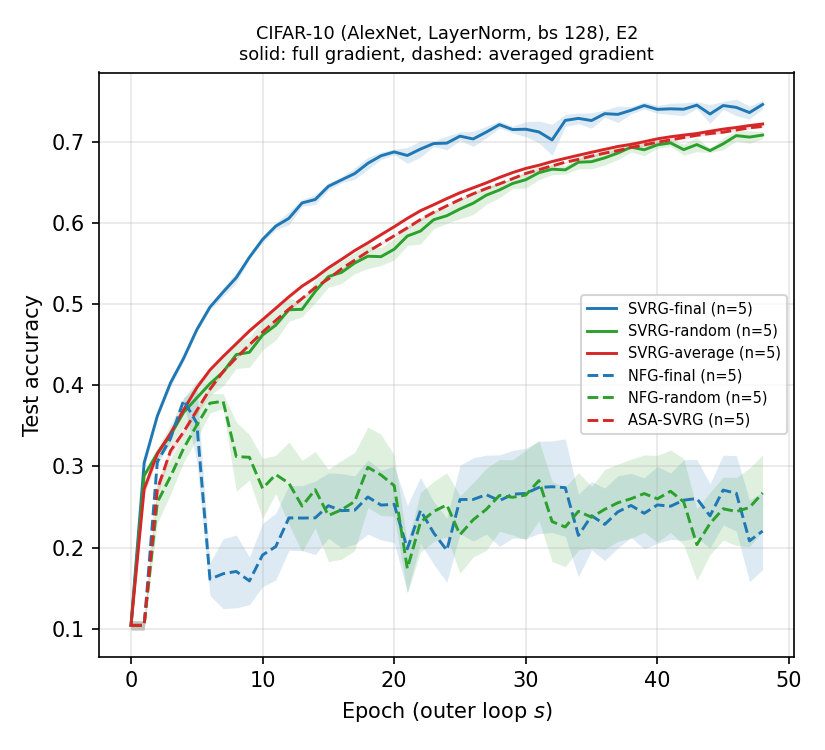

e2_accuracy_grad.png


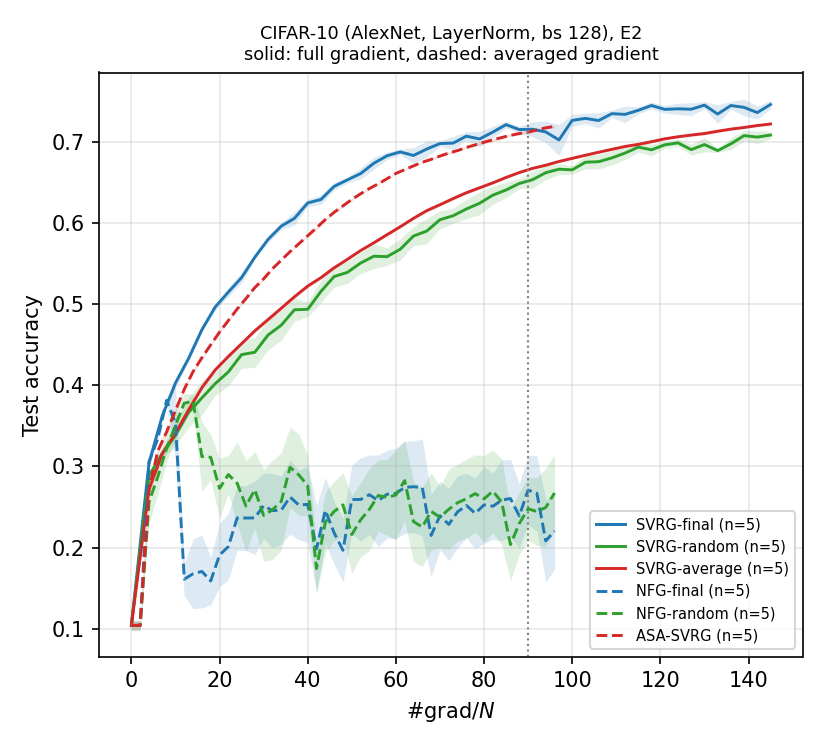

e2_approx_cos_epoch.png


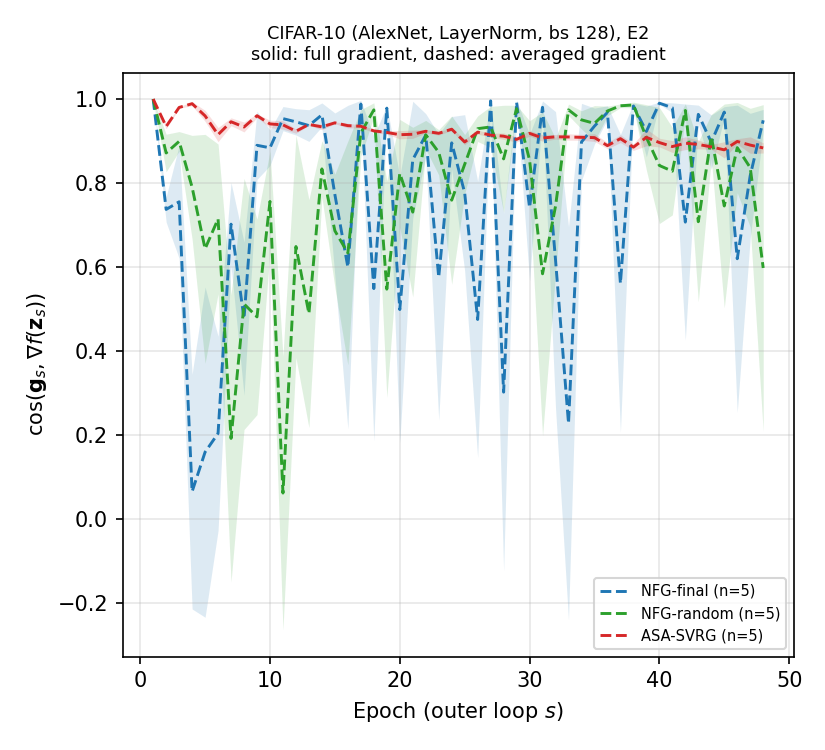

e2_approx_cos_grad.png


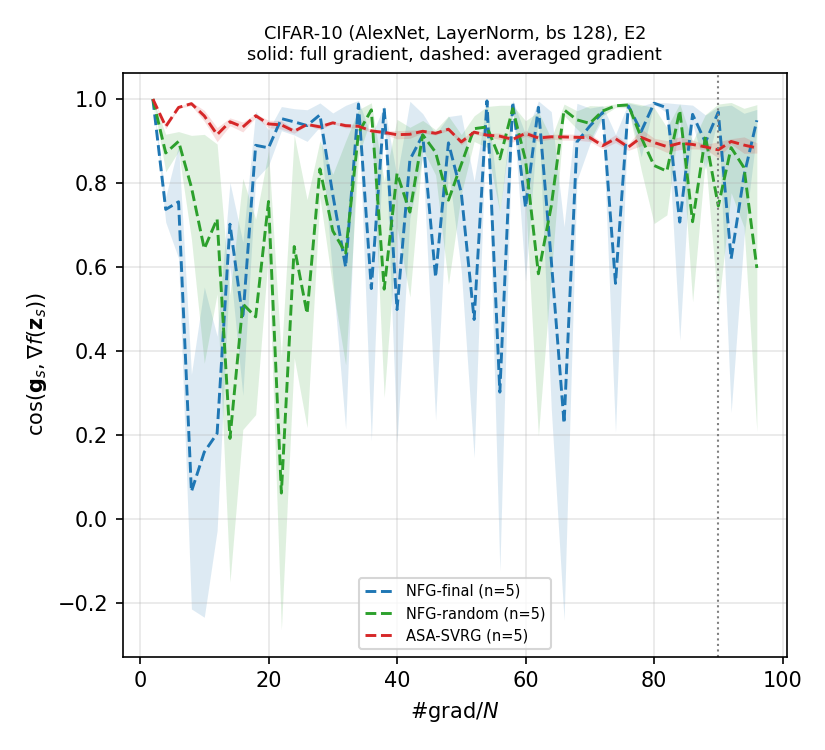

e2_approx_error_epoch.png


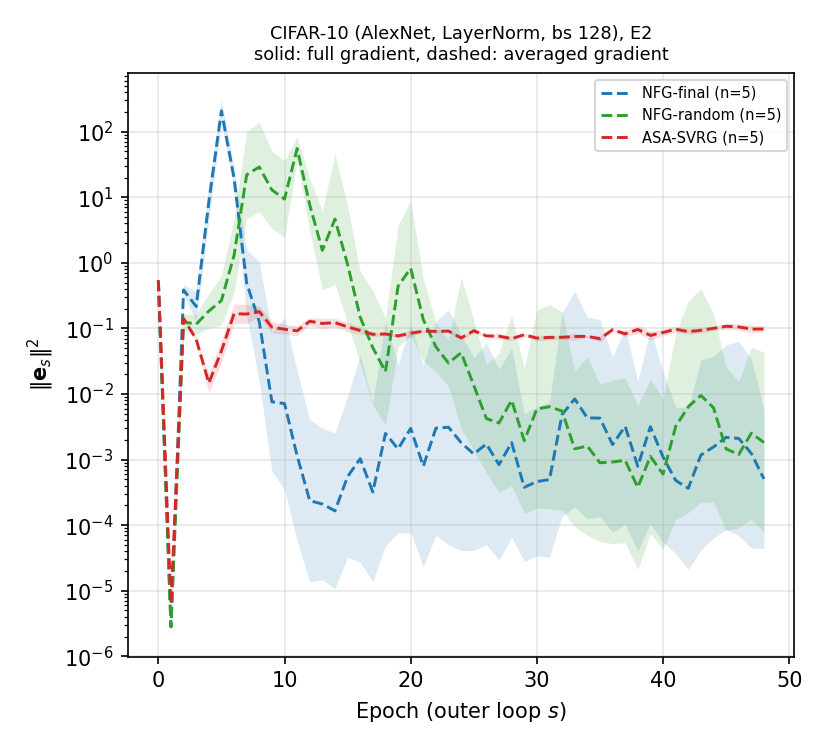

e2_approx_error_grad.png


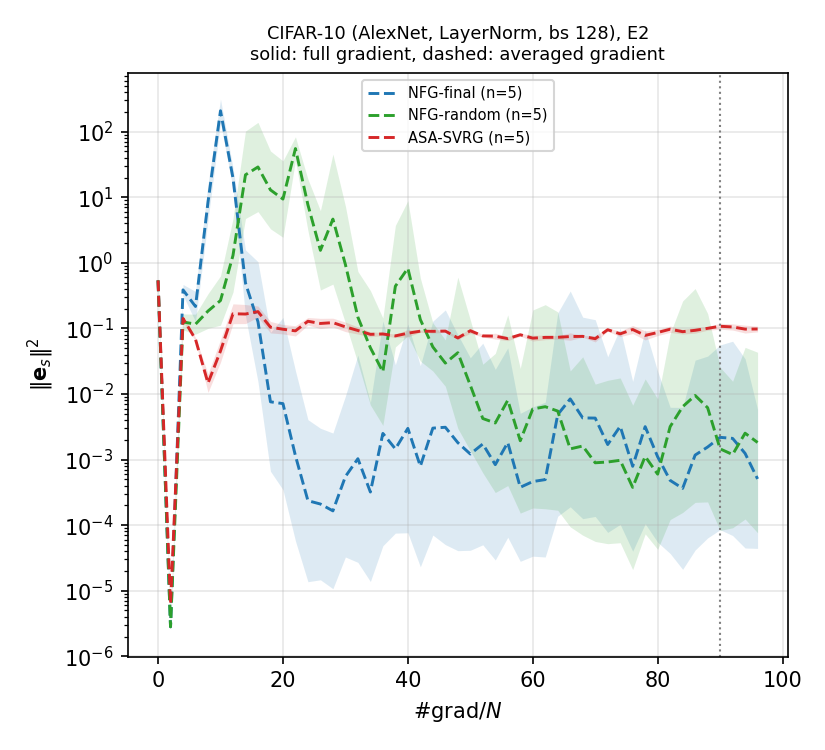

e2_loss_epoch.png


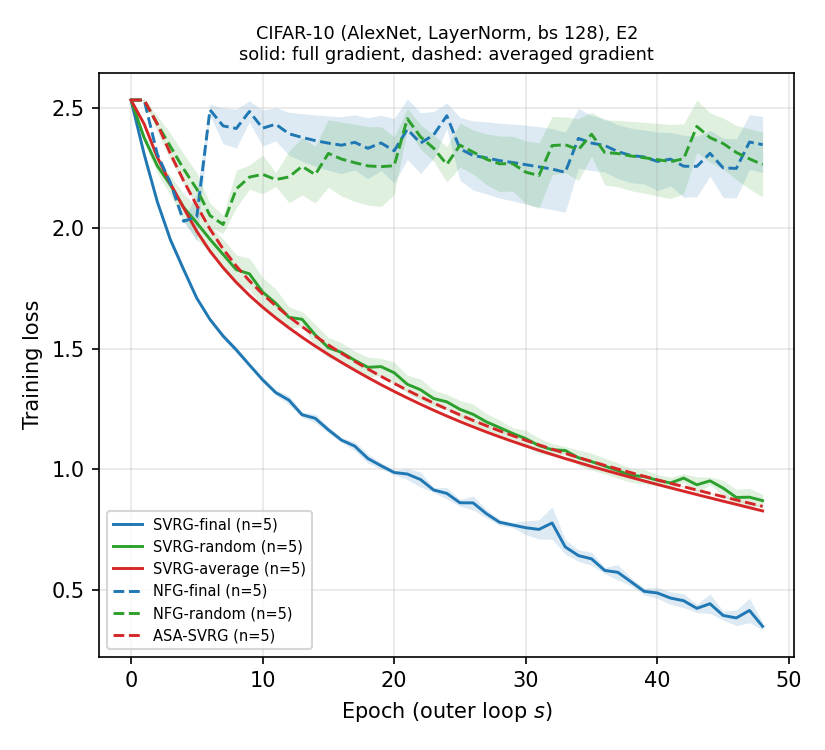

e2_loss_grad.png


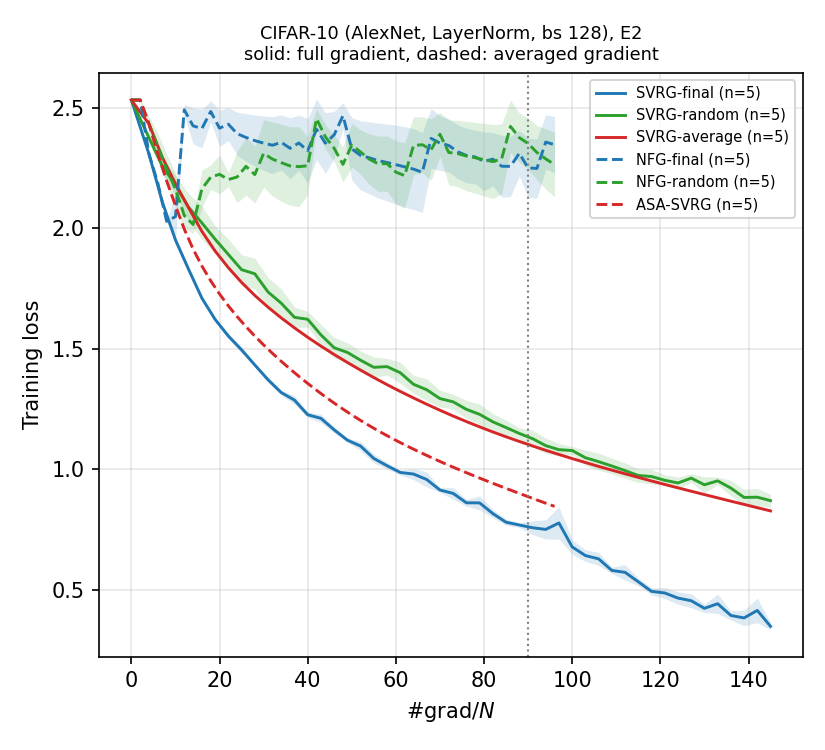

e2_omega_per_K_epoch.png


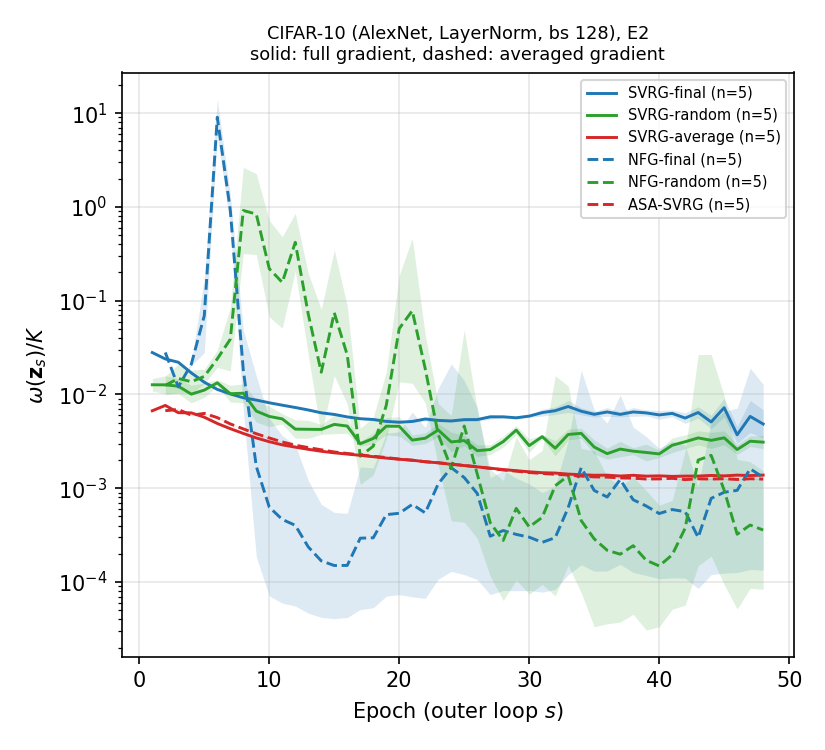

e2_omega_per_K_grad.png


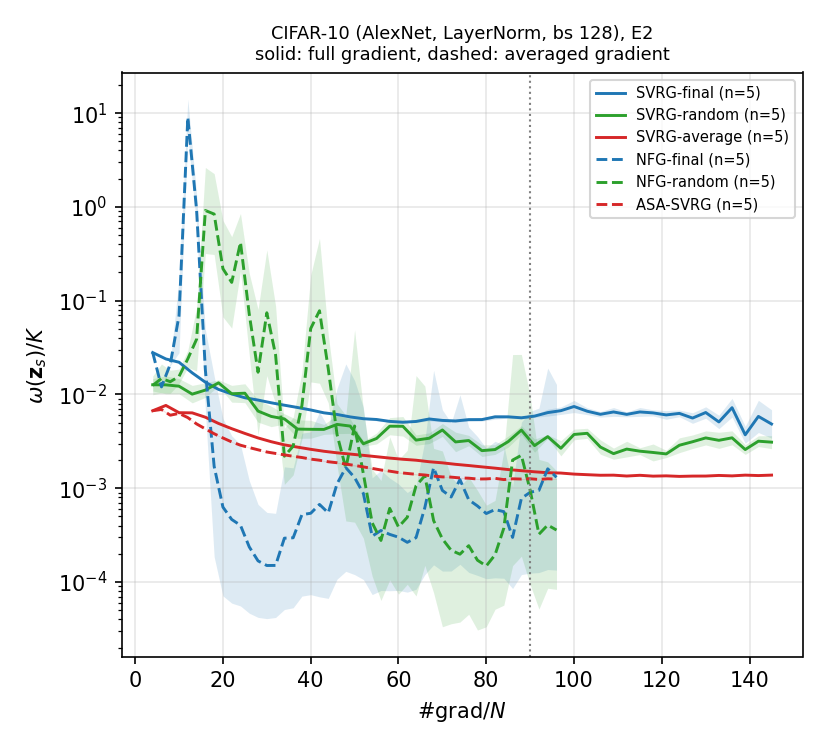

e2_omega_ratio_epoch.png


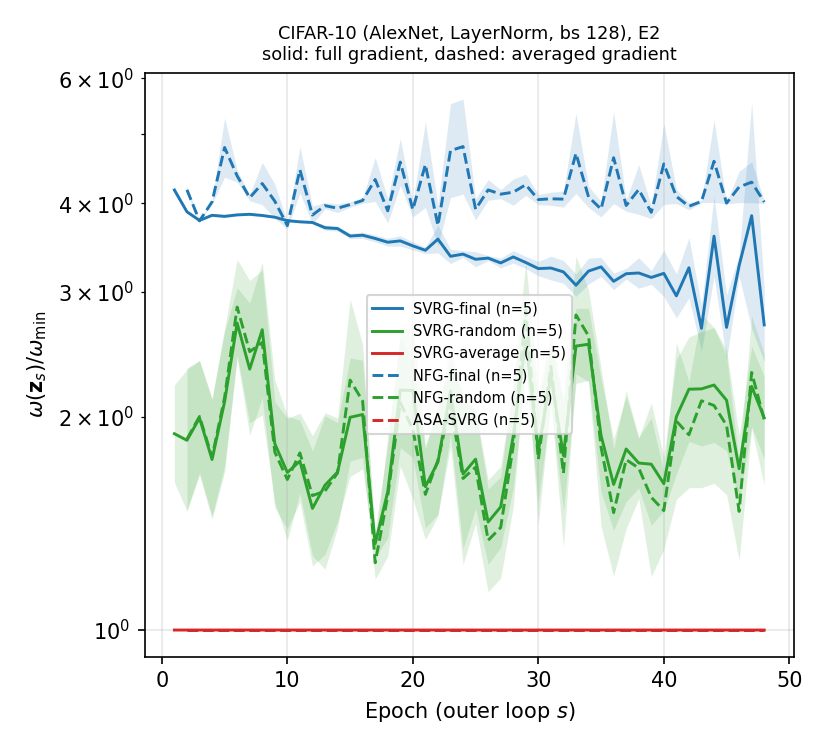

e2_omega_ratio_grad.png


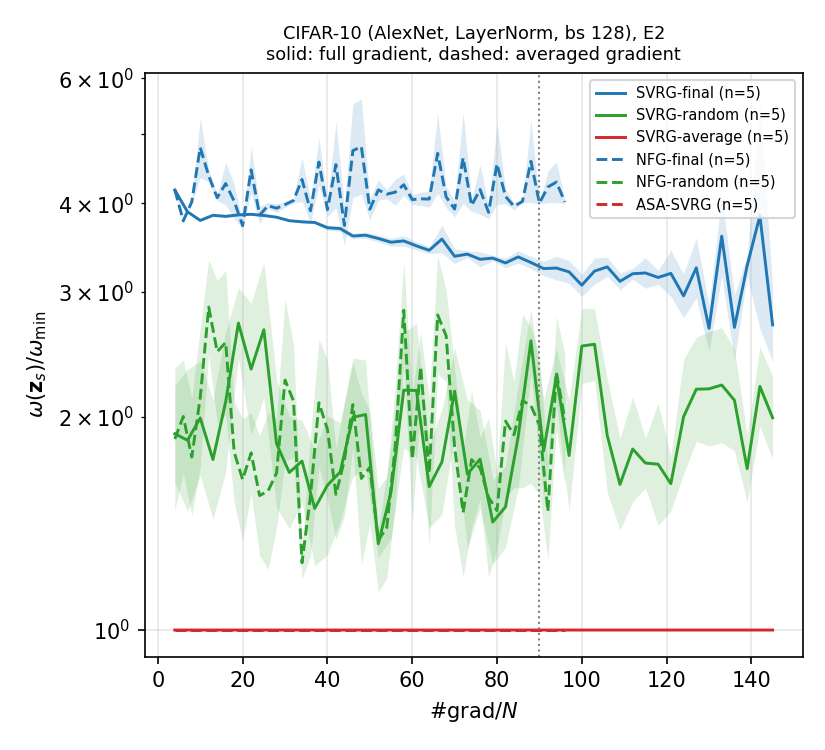

e2_omega_vs_approx_error_epoch.png


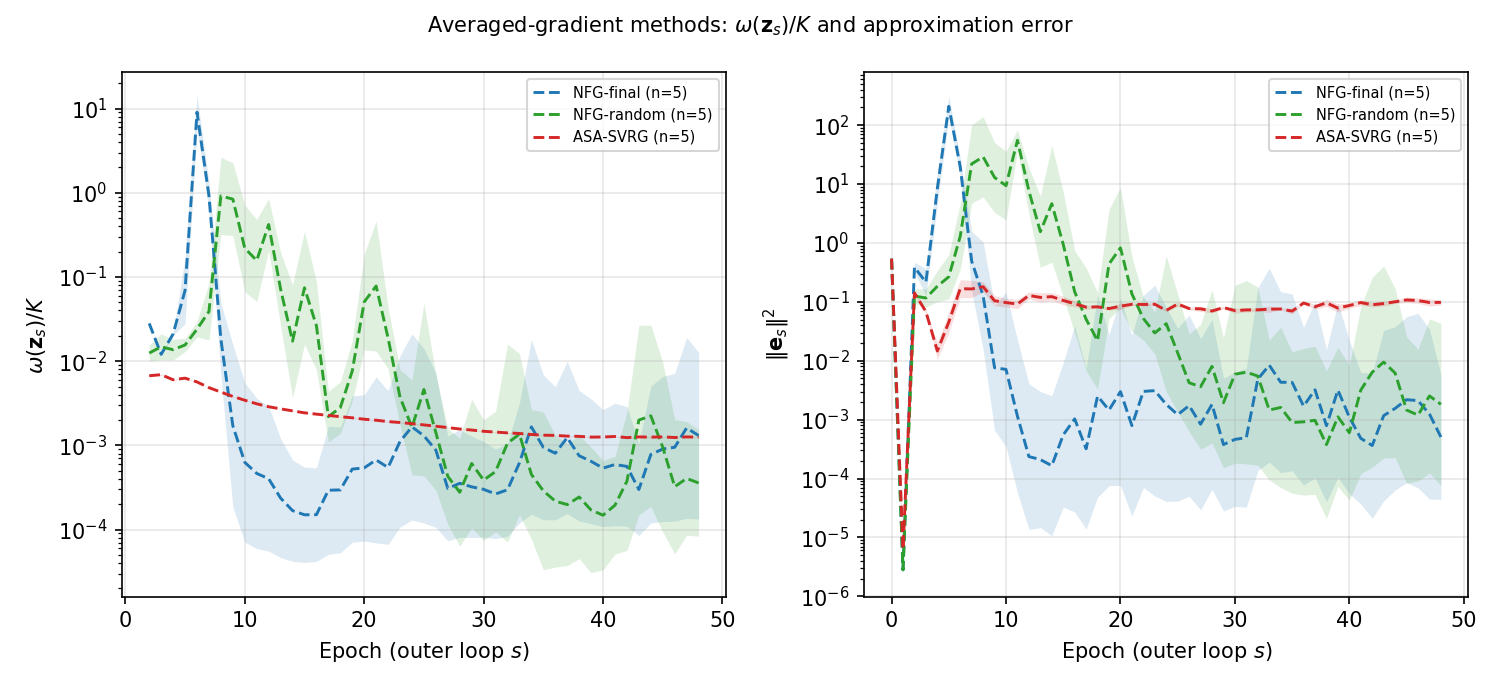

e2_pair_average_epoch.png


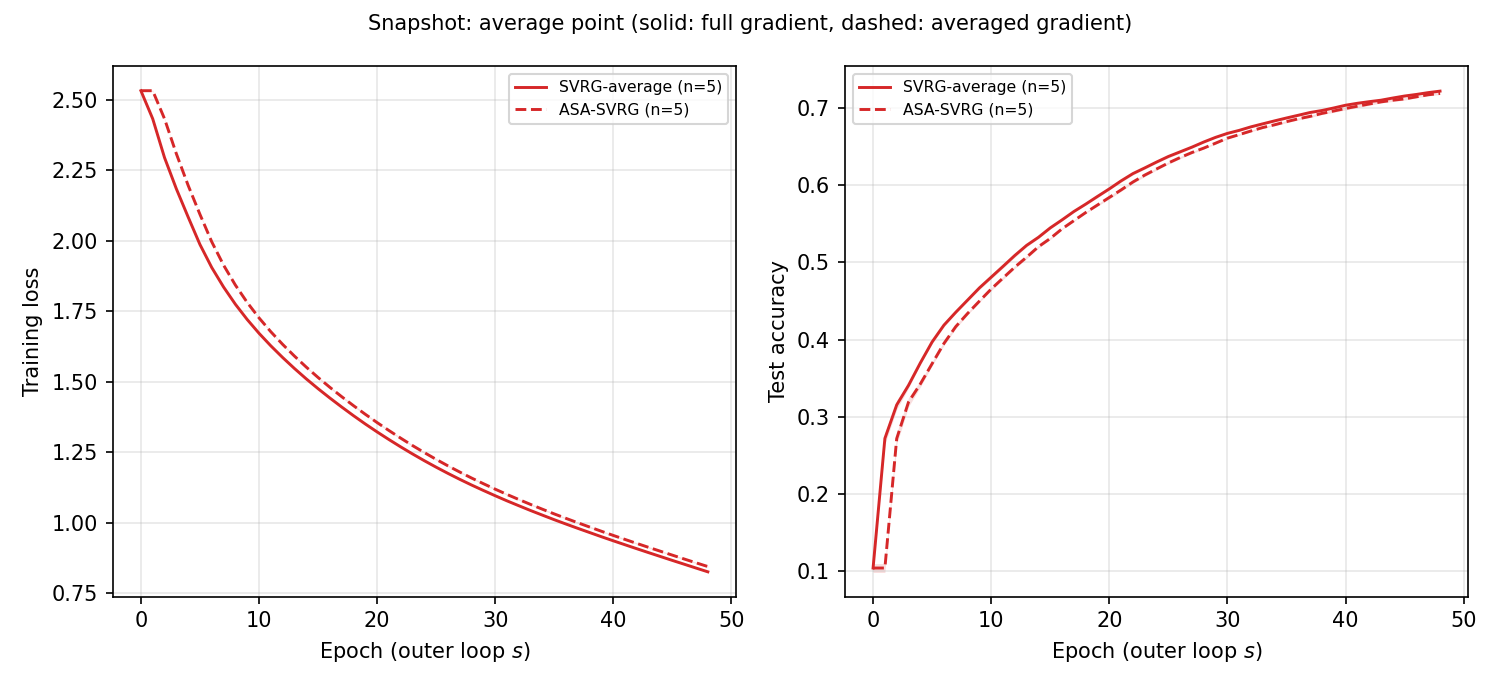

e2_pair_final_epoch.png


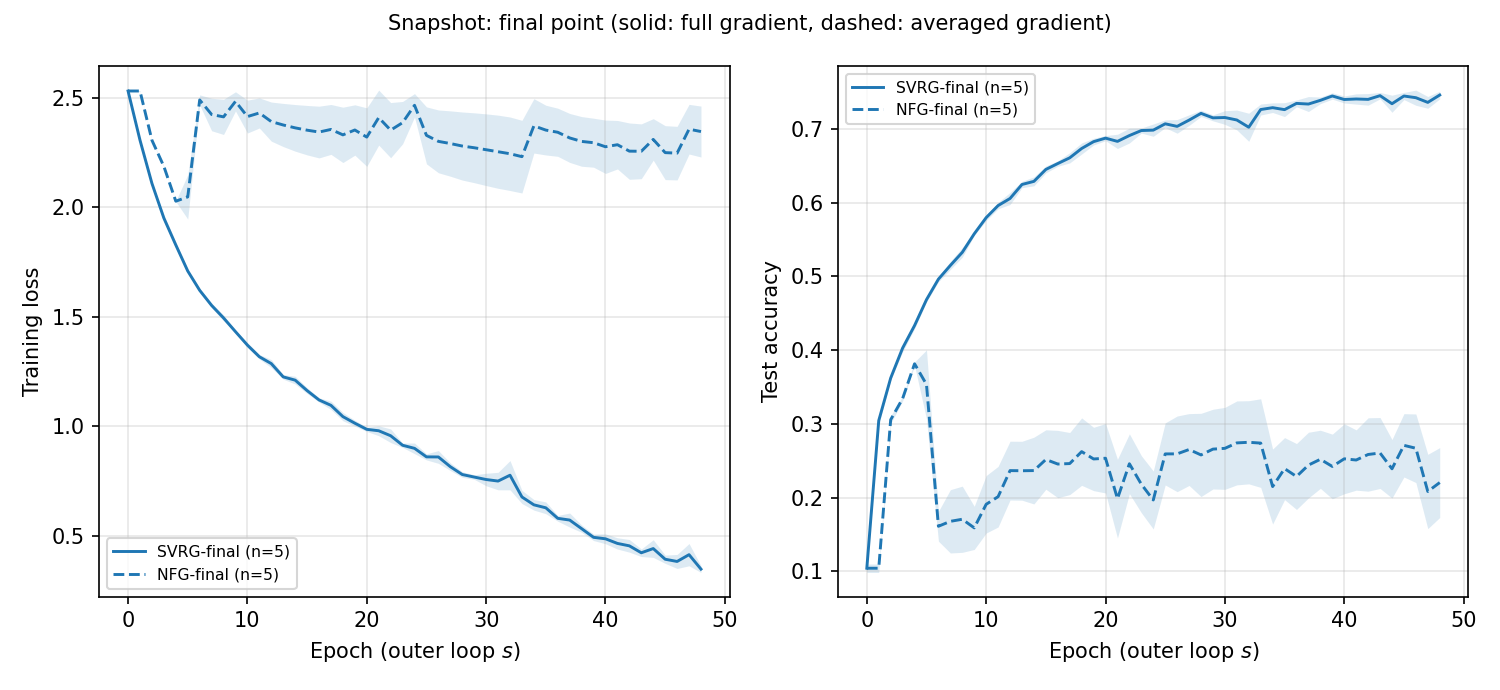

e2_pair_random_epoch.png


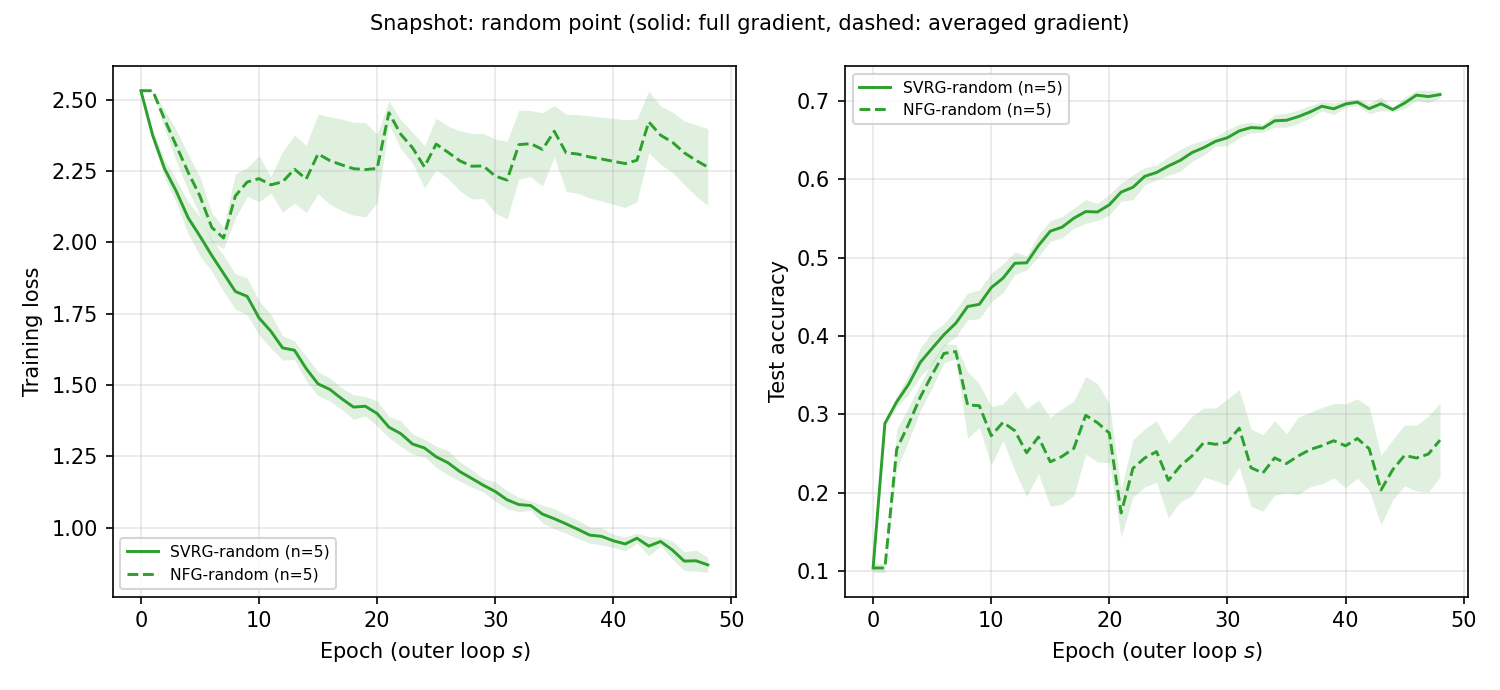

e2_rel_approx_error_epoch.png


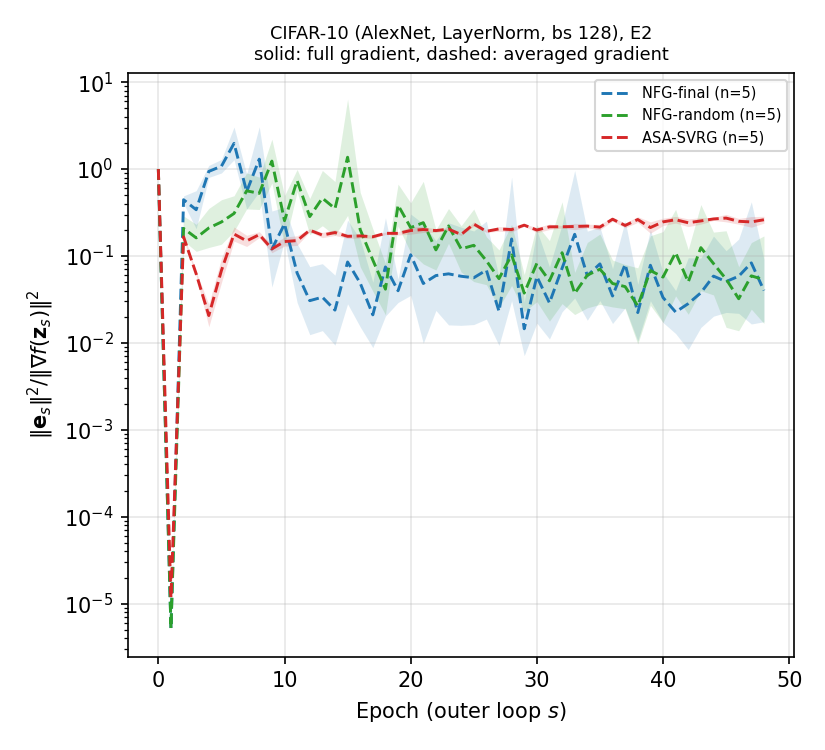

e2_rel_approx_error_grad.png


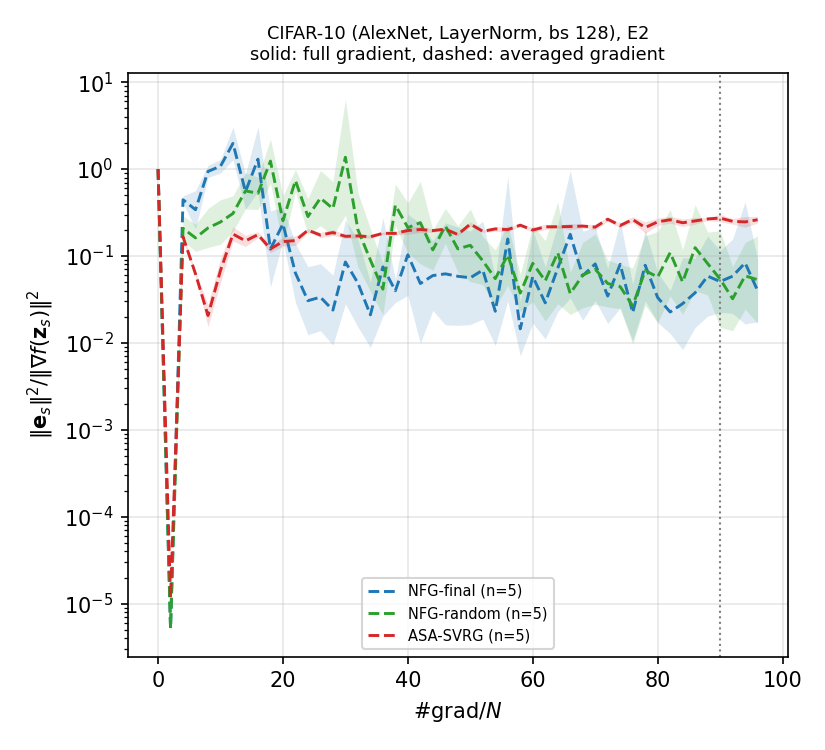

In [3]:
from IPython.display import Image

for name in sorted(os.listdir(a.FIGURE_DIR)):
    if name.endswith(".png"):
        print(name)
        display(Image(os.path.join(a.FIGURE_DIR, name)))

## 手法と指標を選んで描く

`SELECTED_METHODS` に `a.METHODS` の手法名，`METRIC` に `a.METRIC_PANELS` のキー，`AXIS` に `"x"`（$ \#\mathrm{grad}/N $）または `"epoch"` を指定する．

In [4]:
import matplotlib.pyplot as plt

SELECTED_METHODS = ["SVRG", "SVRG_average", "NFG_SVRG", "ASAI_SVRG"]
METRIC = "accuracy"
AXIS = "epoch"

runs = a.load_runs()
key, log_scale, ylabel = a.METRIC_PANELS[METRIC]
fig, ax = plt.subplots(figsize=(5.5, 5))
a._plot_metric(ax, runs, SELECTED_METHODS, key, AXIS, log_scale, ylabel)
ax.legend(fontsize=7)
plt.show()

/tmp/ipykernel_2011342/3770186350.py:12: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
